# Multi-modal Contrastive Analysis (MoCAVI)

Multi-modal Contrastive Analysis (MoCAVI) is a generative model designed to analyze single-cell multi-omics data.
MoCAVI learns to distinguish between a "background" and "target" conditions by integrating information across genes, proteins, and chromatin accessibility. 

MoCAVI is designed to learn two complementary latent spaces:     
    - a "background" latent space that captures variation shared across all cells (e.g., baseline biology like cell cycle, unknown batches),    
    - a "salient" latent space that captures variation unique to a target subset (e.g., perturbations, disease-affected patients) relative to a background subset (e.g., unperturbed cells, unaffected patients).

This tutorial will walk you through setting up, training, and interpreting a MoCAVI model using a single-cell data from a perturbation study with three modalities.

MoCAVI is implemented using scvi-tools.

In [1]:
import os

import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import seaborn as sns
import torch

from mocavi import MoCAVIModel

# make sure cuda is available
print("CUDA available:", torch.cuda.is_available())

scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
Seed set to 0


CUDA available: True
Last run with scvi-tools version: 1.3.0


## Application of MoCAVI to a compound-based screen of CD4+ T-cells

For this case study, we will re-analyze the data from the accompanying manuscript. It is a drug-screening experiment on CD4+ T-cells, generated by the lab of Kelvin Chen at the University of Osaka. In this study, CD4+ T cells were treated with a panel of kinase inhibitors at three different doses (100 nM, 1 µM, and 10 µM). Each unique combination of a compound and its dose represents a specific treatment condition.

The screen was conducted on primary human and mouse T-cells undergoing T-cell activation, only the human arm of the screen will be used as an example in this tutorial. 

The screen was performed across three experimental plates. Cells in each well of each plate have been treated with a different treatment.  In each plate, the two control wells included unstimulated cells (baseline) and stimulated cells treated only with the vehicle (DMSO), serving as the negative control for drug effects under stimulation. Cells from two different donors were used in each well.

### Setting Up the Data

To get started, download the data used in the tutorial

```bash
mkdir data && cd data
curl -L -A "Mozilla/5.0" -o human_icCITE_seq_filtered.h5ad "https://figshare.com/ndownloader/files/55582163?private_link=49ffd57d7316562c54aa"
cd ..
```

If the curl command does not work, please download the file manually from the link using a web browser.

The dataset used as an example has already been preprocessed. 
Preprocessing steps include: 
- cell assignment to a well and plate 
- highly variable gene filtering

Description of these steps are available in the [reproducibility repository](https://github.com/romain-lopez/mocavi-reproducibility).

In [2]:
# let's load the data
out = "../data/human_icCITE_seq_filtered.h5ad"
adata = sc.read_h5ad(out)
adata.uns["adt_select_names"] = adata.obsm["adt_select"].columns.tolist()
adata

AnnData object with n_obs × n_vars = 45325 × 5366
    obs: 'Total_UMI', 'Mouse_UMI', 'Human_UMI', 'Percent_Mouse_UMI', 'Percent_Human_UMI', 'Mouse_MT_UMI', 'Human_MT_UMI', 'Percent_Mouse_MT_UMI', 'Percent_Human_MT_UMI', 'Species_Annot_RNA', 'library', 'hto_label', 'ct_label', 'Total_TSB', 'Total_ADT', 'Log_Total_UMI', 'Log_Total_TSB', 'Log_Total_ADT', 'treatment', 'pathway', 'target', 'treatment_alpha', 'n_counts', 'score_s', 'score_g2m', 'donor', 'batch', '_scvi_labels', '_scvi_batch', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_symbols', 'symbols', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'adt_select_names', 'all_to_remove', 'ct_label_colors', 'donor_colors', 'hto_label_colors', 'hvg', 'leiden', 'leiden_colors', 'library_colors', 'log1p', 'neighbors', 'pathway_colors', 'target_colors', 'totalvi_energy_distance', 'totalvi_energy_distance_null

In [3]:
# get compound and dose from treatment annotation
adata.obs["compound"] = adata.obs["treatment"].str.split("_").str[0]
adata.obs["dose"] = pd.Categorical(
    adata.obs["treatment"].str.split("_").str[1], categories=["100nM", "1uM", "10uM"], ordered=True
)

In this dataset, each cell has been treated with a specific kinase inhibitor at a certain dose, with the exception of two type of control conditions (non-stimulated and DMSO-treated stimulated cells which is denoted as vehicle).

***Screen design***     
This dataset comes from a 3-plate drug screen experiment, with the following design:
* Doses: The experiment involved three different doses. Each of the three plates corresponds to one specific dose.
* Compounds: Within each plate, individual wells were treated with a different compound.    

***Barcoding and Sequencing***    
To identify the origin of each cell after pooling, a two-level barcoding system was used:
* Hash-Tag Oligonucleotides (HTOs) were used to label the plates. Since each plate represents one dose, the `hto_label` tells you the dose each cell received.
* Cell Tags (CTs) were used to label the wells. Since each well contains one compound, the `ct_label` tells you the compound each cell was treated with.


The batch annotation is defined as the combination of the sequencing library, and plate.

Without counting the Vehicle and No Stim controls, there are 56 kinase inhibitors and 165 treatments. Several compound:dose combinations have been excluded during preprocessing as there were not enough cells remaining for analysis. We recommend discarding treatments with not enough cells. Here, we kept treatments with at least 45 cells to be able to accurately estimate their distribution in the salient latent space.

In [4]:
# have a look at the compounds used, the control conditions Vehicle and Not Stim are also present
adata.obs["compound"].unique()

array(['MK-3903', 'Saracatinib', 'Linifanib', 'OSU-03012', 'Solcitinib',
       'JX06', 'AS1517499', 'Vehicle', 'ERK5-IN-1', 'TBHQ', 'Selumetinib',
       'Pazopanib', 'AZD1480', 'WAY-333875', 'Crizotinib', 'No stim',
       'Metformin HCl', 'Ridaforolimus', 'Leflunomide', 'Dasatinib',
       'Doramapimod', 'Cabozantinib', 'Acetylcysteine',
       'Cabozantinib malate', 'Wedelolactone', 'SB216763', 'Stattic',
       'Dovitinib', 'GSK690693', 'Vatalanib', 'Roscovitine', 'Mesalamine',
       'Refametinib', 'Taletrectinib', 'Nifedipine', 'PF-4708671',
       'SP600125', 'Everolimus', 'ASP4132', 'Sorafenib', 'Tozasertib',
       'BX-795', 'PI-103', 'GSK429286A', 'Ethyl gallate', 'Axitinib',
       'Gefitinib', 'Benidipine HCl', 'Vidarabine', '8-Bromo-cAMP',
       "GSK'963", 'Lenvatinib', 'Pitavastatin Calcium', 'SB203580',
       'Amuvatinib', 'Foretinib', 'Flavopiridol', 'Triciribine'],
      dtype=object)

In [5]:
# look at the top number of cells per treatment = compound + dose
adata.obs["treatment"].value_counts().head(10)

treatment
No stim_10uM_H           782
No stim_100nM_H          679
Refametinib_10uM_H       671
No stim_1uM_H            606
GSK690693_10uM_H         587
Vehicle_10uM_H           538
Selumetinib_10uM_H       525
Everolimus_10uM_H        510
Ridaforolimus_10uM_H     505
Ridaforolimus_100nM_H    472
Name: count, dtype: int64

### Assigning cells to target vs baseline

One important point when applying MoCAVI (or other contrastive analysis methods such as ContrastiveVI or contrastivePCA) is to carefully define the target and background conditions. With single-cell profiling of perturbation effects, it is quite common that many perturbations will have undiscernable effect. Including those perturbations in the target condition can dilute the signal and reduce the power to detect meaningful differences.

When we apply MoCAVI, we advise to carefully select the target and background conditions based on prior knowledge or preliminary analysis. In the manuscript, we computed the energy distance on the latent space of a baseline model (e.g., totalVI) to identify treatments that had a significant effect compared to the Vehicle cells. Treatments with no significant effect were assigned to the background condition. Please refer to the manuscript and the reproducibility repo for more details on this selection step.

In [6]:
# specify the baseline environment and the target environments
all_to_remove = adata.uns["all_to_remove"]
background_dataset = np.logical_or(
    adata.obs["compound"] == "Vehicle", np.array([x in all_to_remove for x in adata.obs["treatment"]])
)
background_indices = np.where(background_dataset)[0]
target_indices = np.where(~background_dataset)[0]

`background_indices` and `target_indices` contain the indices of the cells assigned to each environment, respectively. They will be used during the VAE training.

### Load AnnData object into MoCAVI and instantiate the model

MoCAVI needs to know where to find each data type, as well as the batch and perturbation labels for each cell. 
We provide this information using the `MoCAVIModel.setup_anndata` method.

For this model, the data should be structured as follows:
* RNA-seq & ATAC-seq (concatenated; **count data**): MoCAVI is designed to receive gene expression and chromatin accessibility counts as a single, concatenated matrix. This matrix should be stored in a specified location, like adata.layers["counts"]. The model is then told how to split this matrix internally using the `n_genes` and `n_regions` parameters during initialization. If no chromatin accessibility counts is available, `n_regions` should be set to zero.   
counts[:, :n_genes] will be treated as RNA. 
counts[:, n_genes : n_genes + n_regions] will be treated as ATAC.   
* ADT (Protein): Raw protein counts are stored separately in adata.obsm (e.g., adata.obsm["adt_counts"]), with the corresponding protein names in adata.uns (here `adata.obsm['adt_select']`). 
* Metadata (adata.obs): The observation-level metadata must include columns for:
    * the batch annotation  
    * the label of each target condition of interest    

In [7]:
# register RNA + ADT + ATAC (regions) if present
MoCAVIModel.setup_anndata(
    adata,
    batch_key="batch",
    labels_key="treatment",
    layer="counts",
    protein_expression_obsm_key="adt_select",
    protein_names_uns_key="adt_select_names",
)

INFO     Using column names from adata.uns['adt_select_names']                                                     


In [8]:
model = MoCAVIModel(
    adata,
    n_genes=adata.n_vars,
    n_regions=0,  # in this example we don't have ATAC-Seq data
    n_salient_latent=15,
    n_background_latent=10,
    n_layers_decoder=2,
    reweighting_mode="auto",
)

It is recommended to review the setup to ensure it is correct

In [9]:
model.view_anndata_setup()

Anndata setup with scvi-tools version 1.3.0.

Setup via `MoCAVIModel.setup_anndata` with arguments:

{
│   'protein_expression_obsm_key': 'adt_select',
│   'protein_names_uns_key': 'adt_select_names',
│   'layer': 'counts',
│   'batch_key': 'batch',
│   'labels_key': 'treatment',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │  10   │
│         n_cells          │ 45325 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  171  │
│        n_proteins        │  83   │
│          n_vars          │ 5366  │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    labels    │ adata.obs['_scvi_labels'] │
│   proteins   │ adata.obsm['adt_select']  │
└──────────────┴───────────────────────────┘

                  batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['batch'] │     D0     │          0          │
│                    │     D1     │          1          │
│                    │     E0     │          2          │
│                    │     E1     │          3          │
│                    │     F0     │          4          │
│                    │     F1     │          5          │
│                    │     G0     │          6          │
│                    │     G1     │          7          │
│                    │     H0     │          8          │
│                    │     H1     │          9          │
└────────────────────┴────────────┴─────────────────────┘

                             labels State Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃    Source Location     ┃          Categories          ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['treatment'] │      8-Bromo-cAMP_1uM_H      │          0          │
│                        │     8-Bromo-cAMP_10uM_H      │          1          │
│                        │     8-Bromo-cAMP_100nM_H     │          2          │
│                        │       AS1517499_1uM_H        │          3          │
│                        │       AS1517499_10uM_H       │          4          │
│                        │      AS1517499_100nM_H       │          5          │
│                        │        ASP4132_1uM_H         │          6          │
│                        │        ASP4132_10uM_H        │          7          │
│                        │       ASP4132_100nM_H        │          8          │
│                        │        AZD1480_1uM_H         │          9          │
│                        │        AZD1480_10uM_H        │         10          │
│                        │       AZD1480_100nM_H        │         11          │
│                        │     Acetylcysteine_1uM_H     │         12          │
│                        │    Acetylcysteine_10uM_H     │         13          │
│                        │    Acetylcysteine_100nM_H    │         14          │
│                        │       Amuvatinib_1uM_H       │         15          │
│                        │      Amuvatinib_10uM_H       │         16          │
│                        │      Amuvatinib_100nM_H      │         17          │
│                        │        Axitinib_1uM_H        │         18          │
│                        │       Axitinib_10uM_H        │         19          │
│                        │       Axitinib_100nM_H       │         20          │
│                        │         BX-795_1uM_H         │         21          │
│                        │        BX-795_10uM_H         │         22          │
│                        │        BX-795_100nM_H        │         23          │
│                        │     Benidipine HCl_1uM_H     │         24          │
│                        │    Benidipine HCl_10uM_H     │         25          │
│                        │    Benidipine HCl_100nM_H    │         26          │
│                        │  Cabozantinib malate_1uM_H   │         27          │
│                        │  Cabozantinib malate_10uM_H  │         28          │
│                        │ Cabozantinib malate_100nM_H  │         29          │
│                        │      Cabozantinib_1uM_H      │         30          │
│                        │     Cabozantinib_10uM_H      │         31          │
│                        │     Cabozantinib_100nM_H     │         32          │
│                        │       Crizotinib_1uM_H       │         33          │
│                        │      Crizotinib_10uM_H       │         34          │
│                        │      Crizotinib_100nM_H      │         35          │
│                        │       Dasatinib_1uM_H        │         36          │
│                        │       Dasatinib_10uM_H       │         37          │
│                        │      Dasatinib_100nM_H       │         38          │
│                        │      Doramapimod_1uM_H       │         39          │
│                        │      Doramapimod_10uM_H      │         40          │
│                        │     Doramapimod_100nM_H      │         41          │
│                        │       Dovitinib_1uM_H        │         42          │
│                        │       Dovitinib_10uM_H       │         43          │
│                        │      Dovitinib_100nM_H       │         44          │
│                        │       ERK5-IN-1_1uM_H        │         45          │


### Train the MoCAVI model

In [10]:
train = True  # set to False to load a pre-trained model
save_dir = "./data/model"
os.makedirs(save_dir, exist_ok=True)

In [11]:
max_epochs = 80  # for a complete training
if train:
    # train the model
    model.train(
        max_epochs=max_epochs,
        accerator="auto",
        batch_size=256,
        background_indices=background_indices,
        target_indices=target_indices,
        check_val_every_n_epoch=1,
        early_stopping=True,
        plan_kwargs={
            "n_epochs_kl_warmup": int(0.8 * max_epochs),
        },
    )
    model.save(save_dir, overwrite=True)
else:
    model = MoCAVIModel.load(save_dir, adata)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
You are using a CUDA device ('NVIDIA L40S') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 2/80:   1%|▏         | 1/80 [00:06<08:15,  6.27s/it, v_num=1, train_loss_step=3.71e+3, train_loss_epoch=3.92e+3]

/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 256. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 88. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 80/80: 100%|██████████| 80/80 [04:52<00:00,  3.68s/it, v_num=1, train_loss_step=3.38e+3, train_loss_epoch=3.23e+3]

`Trainer.fit` stopped: `max_epochs=80` reached.


Epoch 80/80: 100%|██████████| 80/80 [04:52<00:00,  3.66s/it, v_num=1, train_loss_step=3.38e+3, train_loss_epoch=3.23e+3]


After running model.train(), the training history is stored in model.history.   

Plotting the negative ELBO helps to verify that learning behaved as expected. We want to see the curves on the training data and validation data to both decrease steadily and then plateau. If the validation loss starts increasing while training loss keeps decreasing, it indicates overfitting.  

<Axes: xlabel='epoch'>

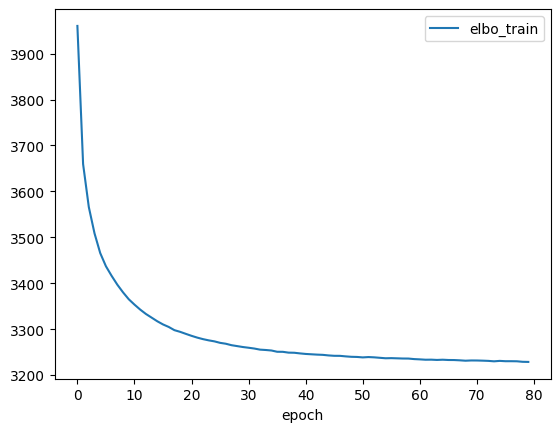

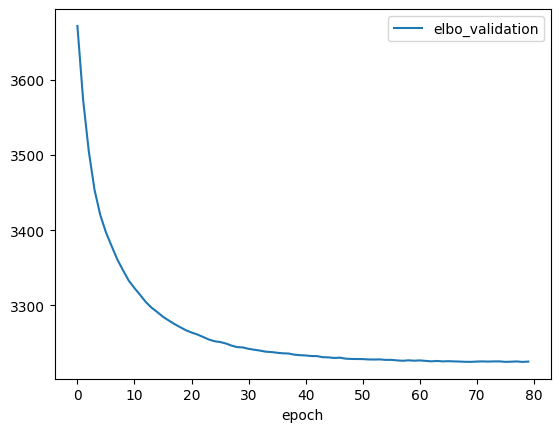

In [12]:
model.history["elbo_train"].plot(label="Train (−ELBO)")
model.history["elbo_validation"].plot(label="Validation (−ELBO)")

### Extract and plot the distribution of the cells in the background and salient latent spaces

From the estimated model, we can get latent representation of the cells in the background and salient latent space and add it to the AnnData object. Then any typical analysis like clustering of cells and treatments can be applied to the latent space of interest.
We will only show here UMAP plots of the two latent spaces for a quick visualization of the kind of signals they capture.

In [13]:
# get salient latent space s
adata.obsm["salient_rep"] = model.get_latent_representation(adata, representation_kind="salient")

In [14]:
# umap of salient latent space
sc.pp.neighbors(adata, use_rep="salient_rep")
sc.tl.umap(adata)
adata.obsm["X_salient_umap"] = adata.obsm["X_umap"].copy()

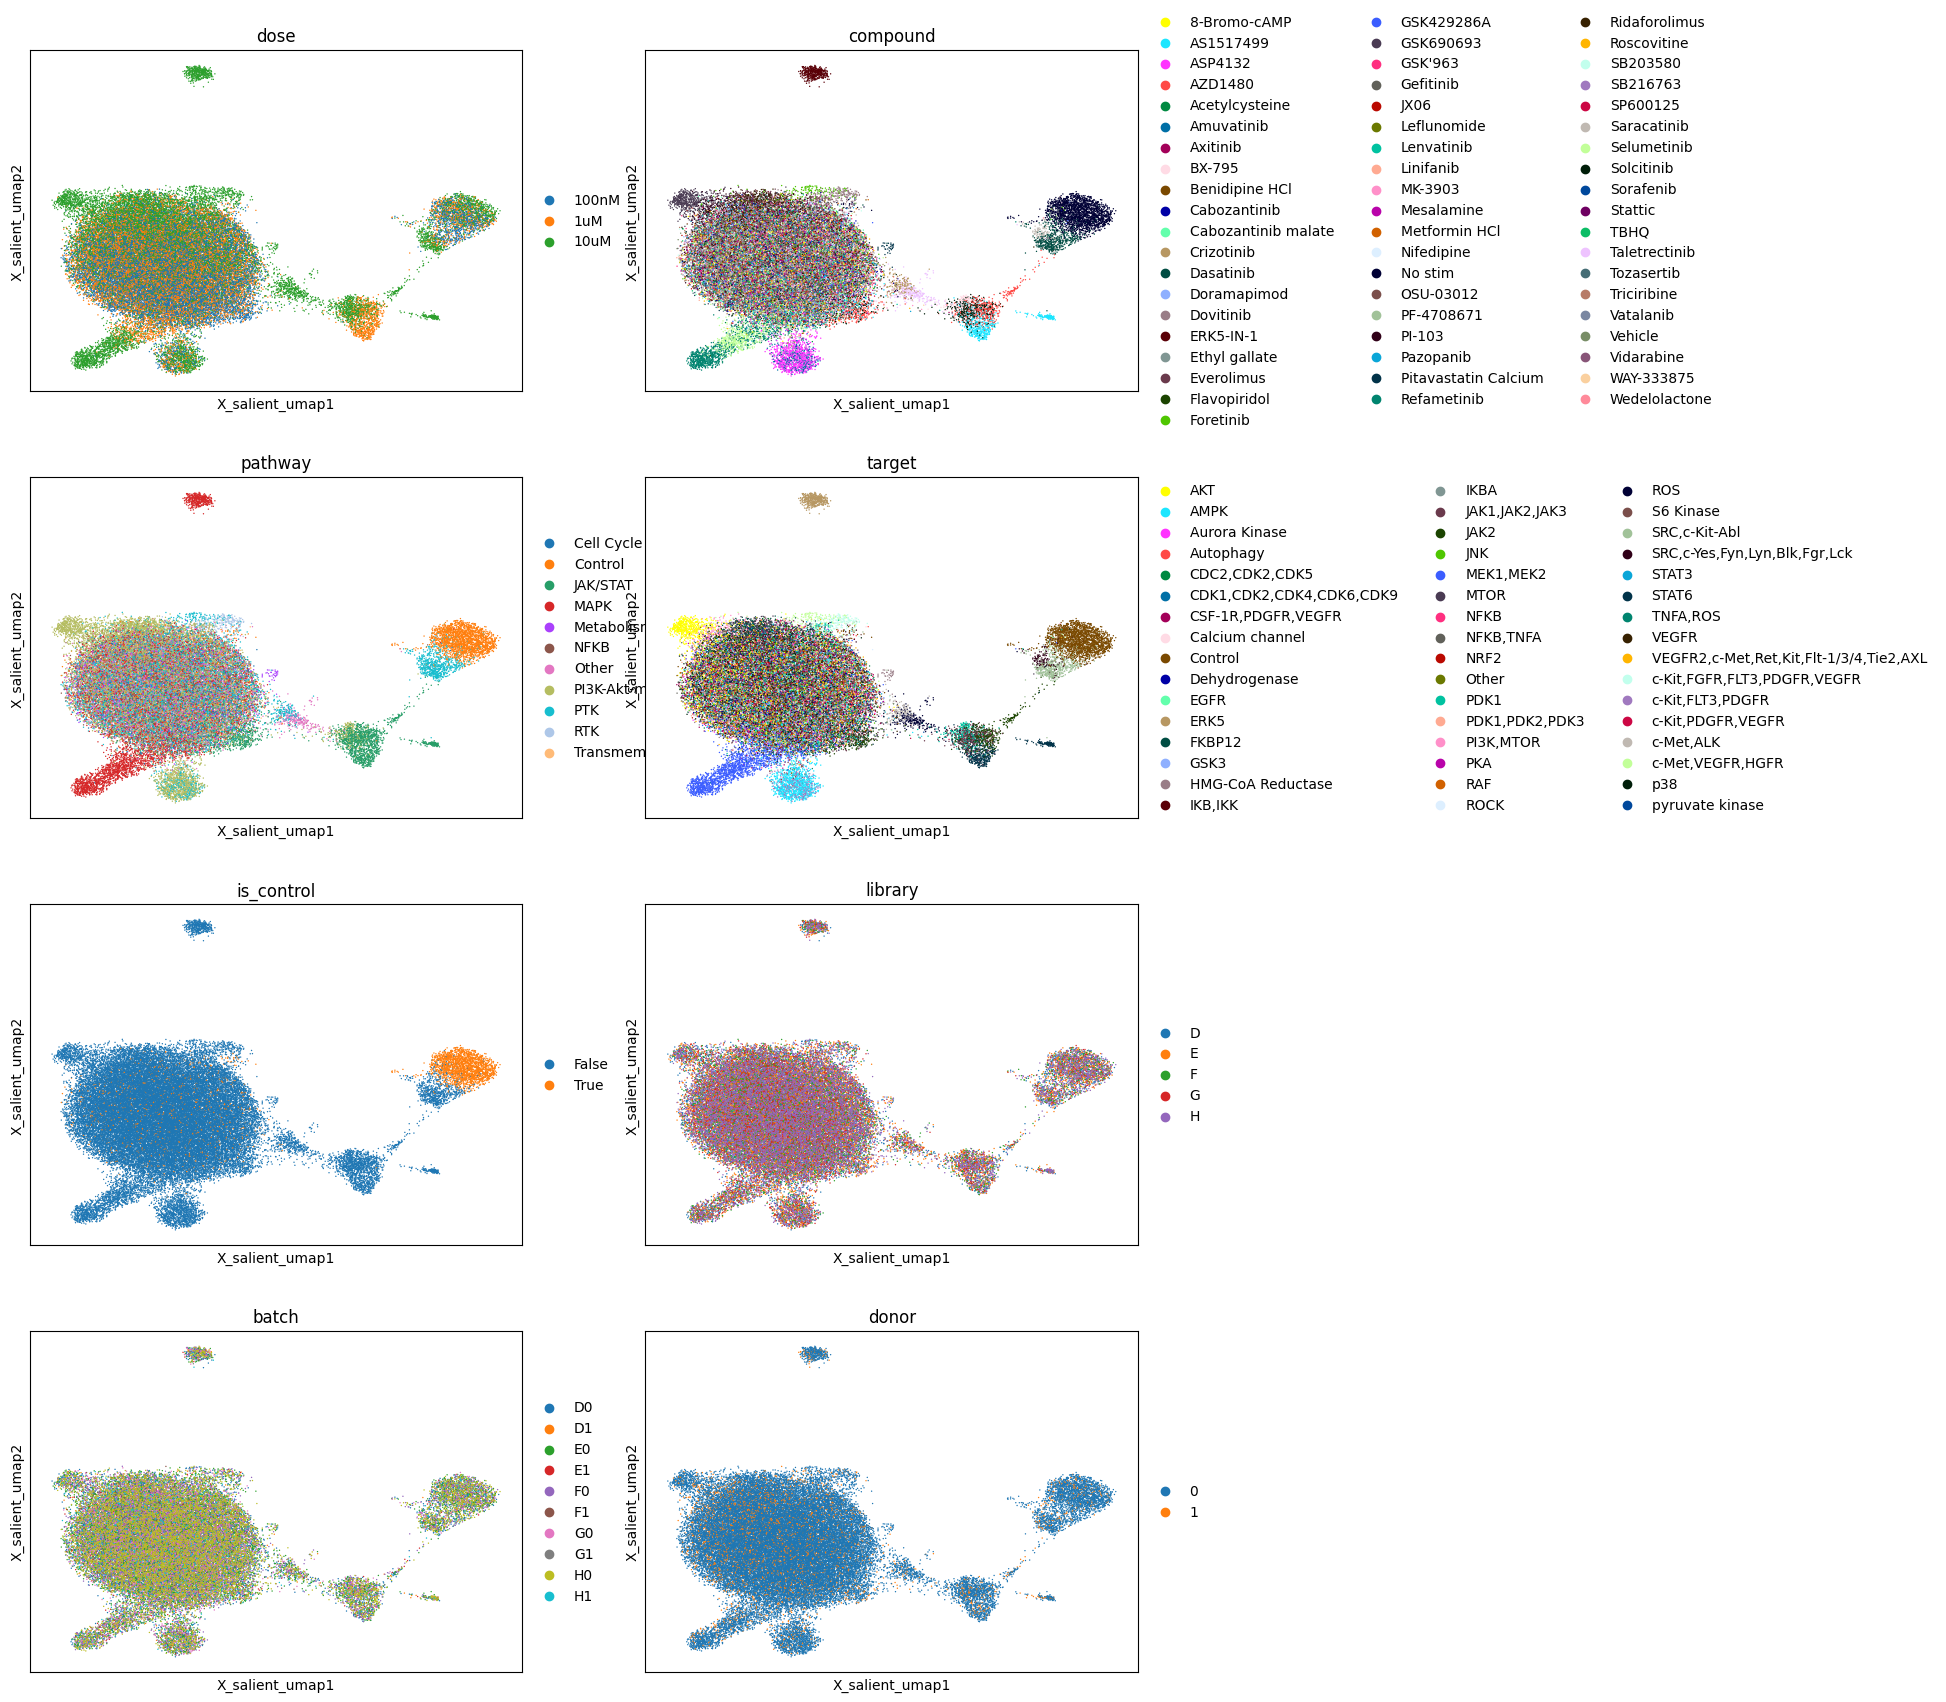

In [15]:
# quick glance at the salient latent space s
adata.obs["is_control"] = adata.obs["compound"].isin(["Vehicle", "No stim"])
sc.pl.embedding(
    adata,
    basis="X_salient_umap",
    color=["dose", "compound", "pathway", "target", "is_control", "library", "batch", "donor"],
    ncols=2,
    size=4,
)

In [16]:
# get background latent space z
adata.obsm["background_rep"] = model.get_latent_representation(adata, representation_kind="background")

In [17]:
# umap of background latent space z
sc.pp.neighbors(adata, use_rep="background_rep")
sc.tl.umap(adata)
adata.obsm["X_background_umap"] = adata.obsm["X_umap"].copy()

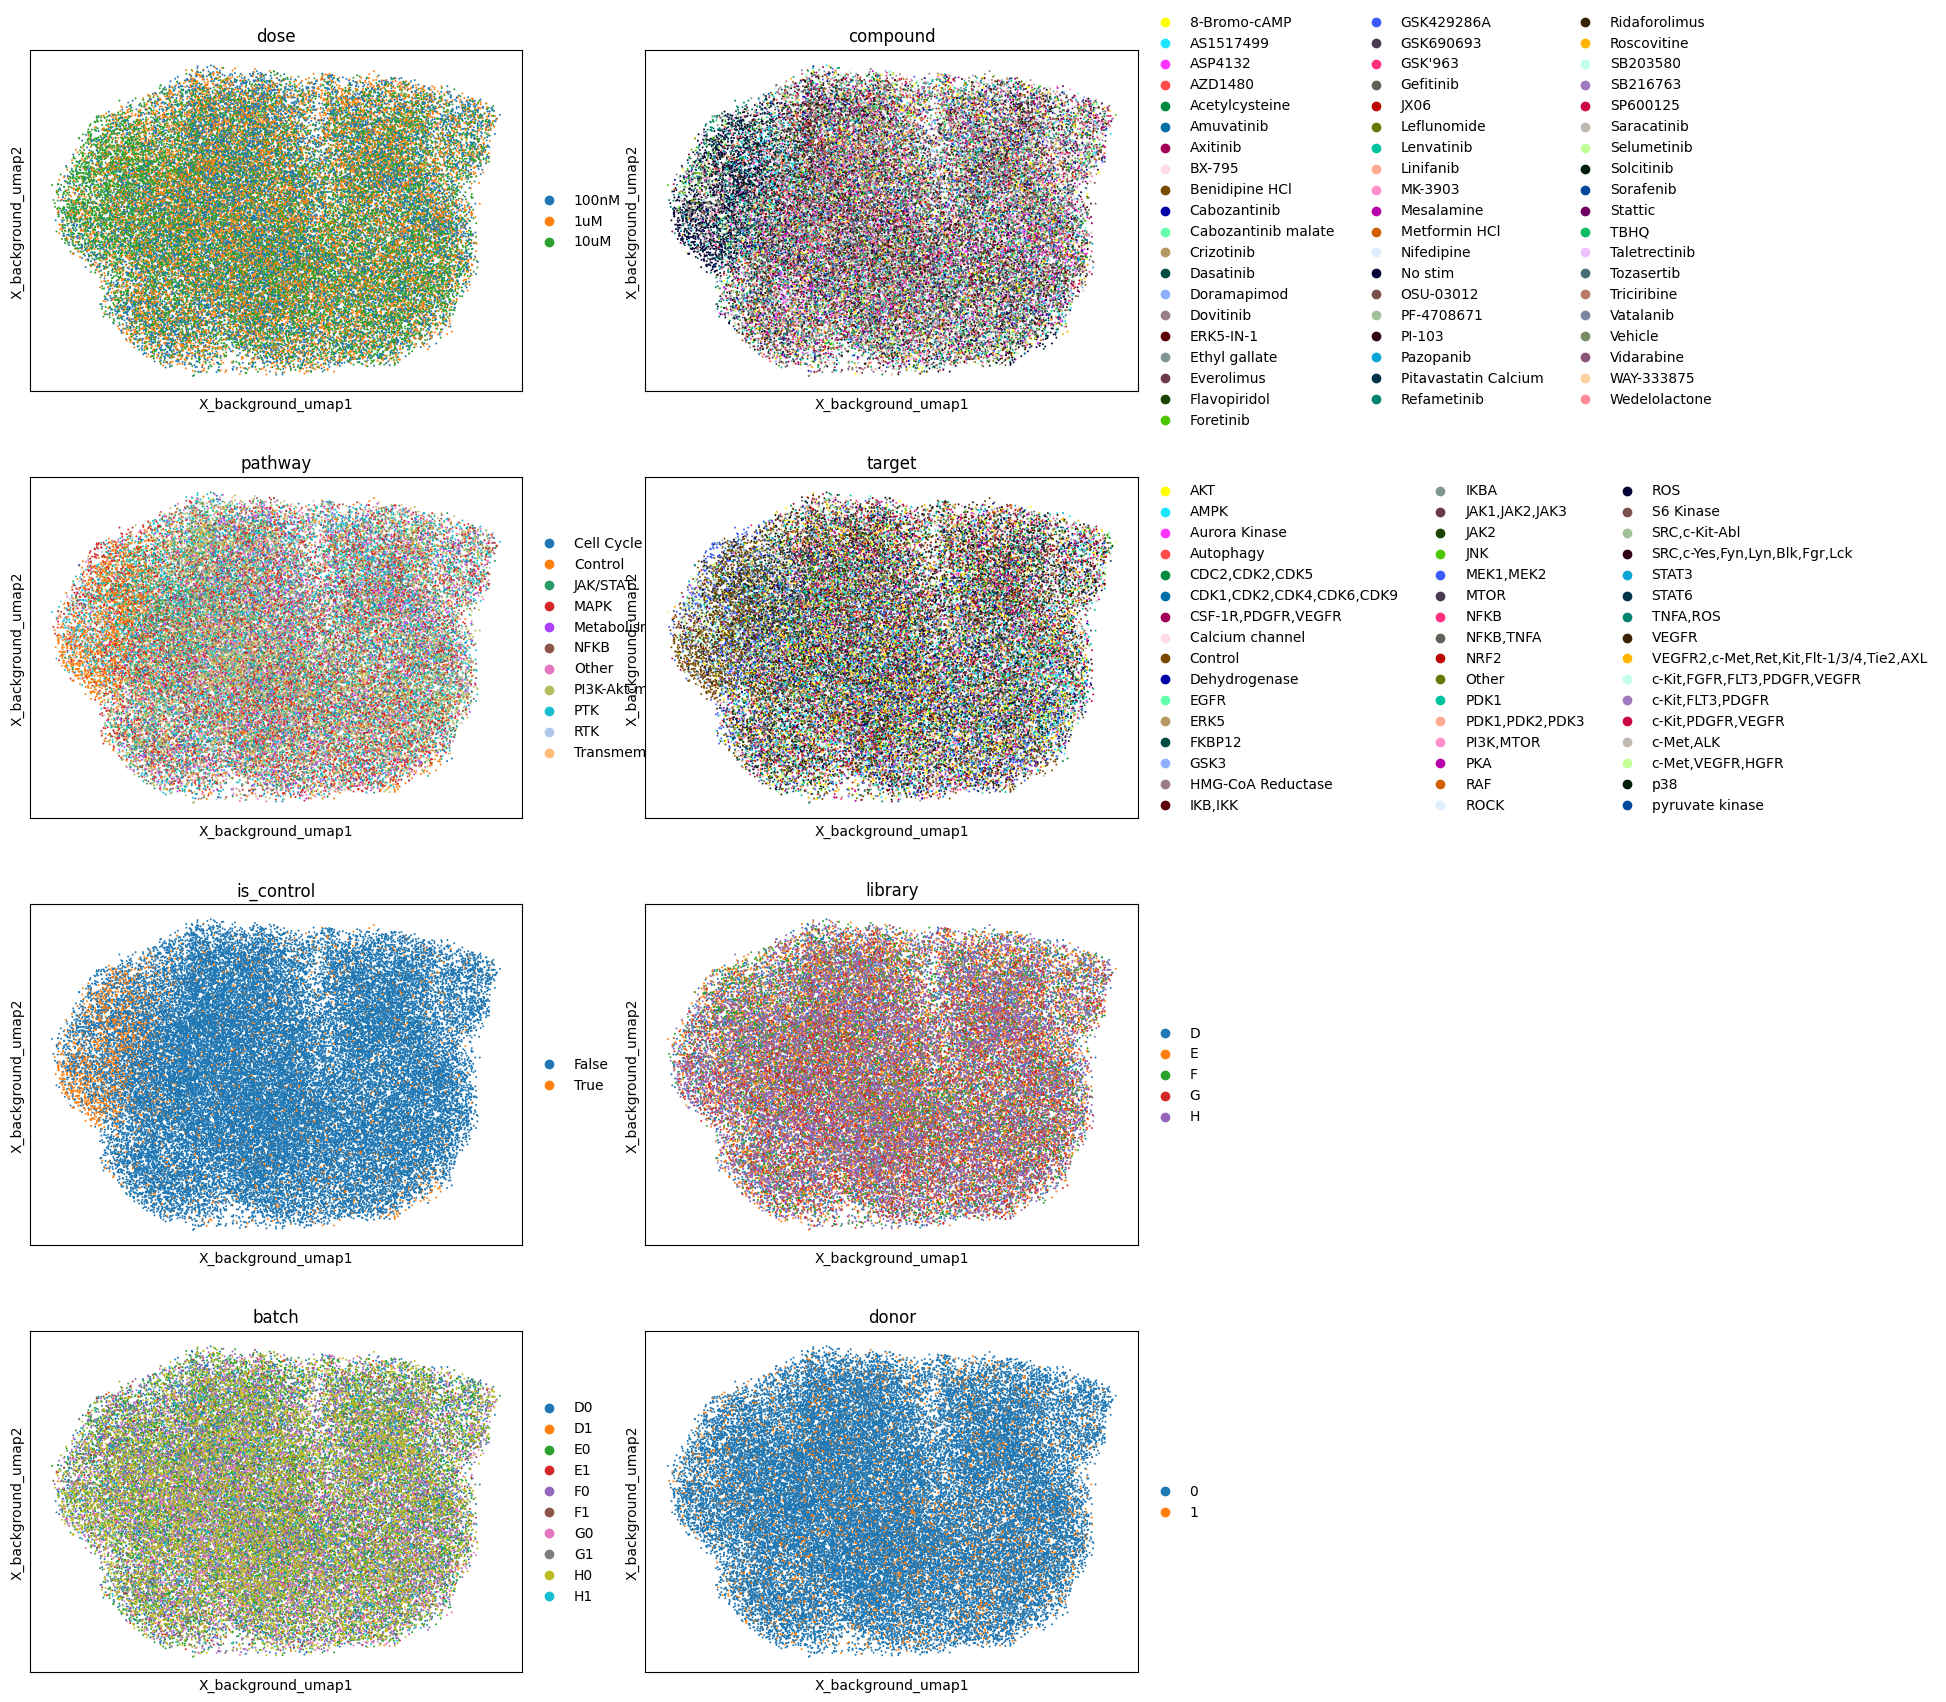

In [18]:
# quick glance at the background latent space z
sc.pl.embedding(
    adata,
    basis="X_background_umap",
    color=["dose", "compound", "pathway", "target", "is_control", "library", "batch", "donor"],
    ncols=2,
    size=8,
)

Is the global cell cycle activity captured in the background or salient space? 
It is captured in the background space, which allows to focus on proliferation patterns specific to treatment in the salient space, if any.

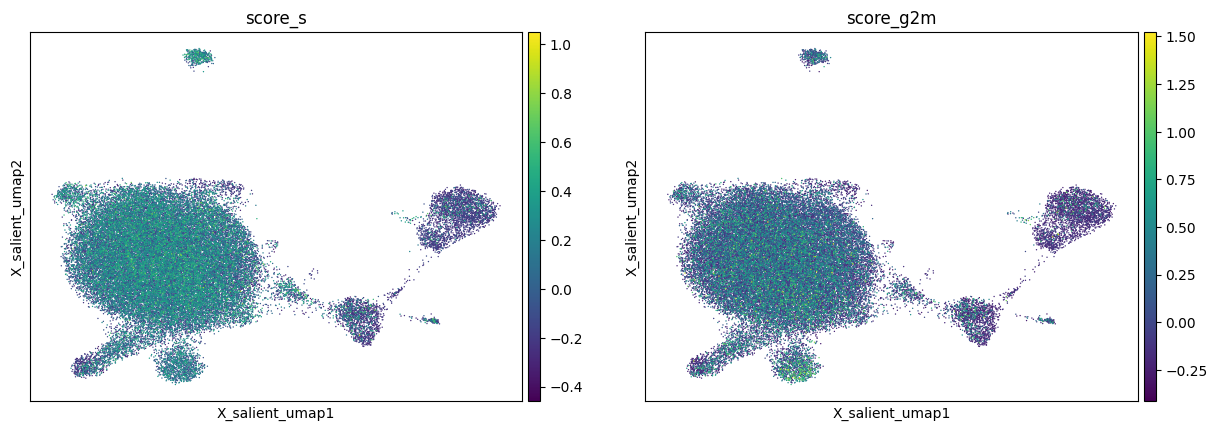

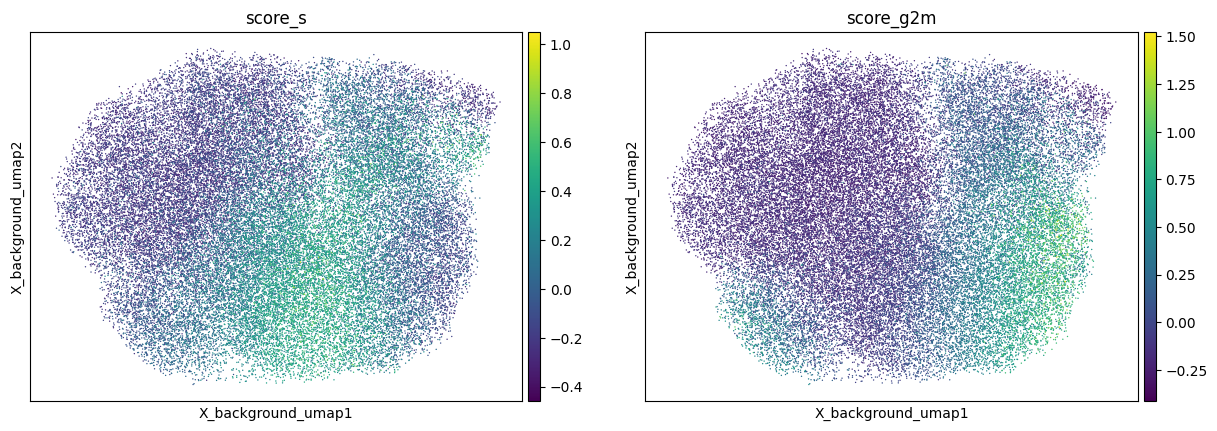

In [19]:
sc.pl.embedding(adata, basis="X_salient_umap", color=["score_s", "score_g2m"], ncols=2, size=4)

sc.pl.embedding(adata, basis="X_background_umap", color=["score_s", "score_g2m"], ncols=2, size=4)

### Synthetic differential abundance

We may want to compare two groups of cells using the decoded gene expression (or protein abundance) inferred by the generative model. In the case of models dedicated to contrastive analysis like ContrastiveVI (Weinberger et al., 2021) or MoCAVI, it can be of particular interest to extract expression patterns specific to a group of cells (e.g. a treatment of interest) using a synthetic control estimated from the background latent space. 
This is referred as the "Salient-specific log fold change (ssLfc) estimation" in MoCAVI. 
For a set of cells of interest, it is done by comparing (i) the decoded profile obtained using the concatenation of both the background and salient latent variables (z, s), to (ii) the decoding obtained with the background only, when the salient signal has been zeroed out (z, 0). Instead of contrasting treated cells to a separate control cohort, it contrasts each treated cell against its own synthetic “vehicle” version. 

We illustrate below how to get results fo the synthetic differential gene expression for a set of treatments of interest.

In [20]:
# perform synthetic differential abundance on selected conditions
conditions_of_interest = [
    "OSU-03012_1uM_H",
    "GSK690693_10uM_H",
    "GSK690693_1uM_H",
    "Stattic_10uM_H",
    "Dovitinib_10uM_H",
    "Saracatinib_1uM_H",
    "Tozasertib_10uM_H",
    "OSU-03012_10uM_H",
    "Foretinib_10uM_H",
    "Ridaforolimus_100nM_H",
    "Ridaforolimus_1uM_H",
    "Everolimus_10uM_H",
    "Ridaforolimus_10uM_H",
    "Everolimus_1uM_H",
    "PI-103_10uM_H",
    "PI-103_1uM_H",
    "Everolimus_100nM_H",
    "Saracatinib_10uM_H",
    "No stim_10uM_H",
    "Dasatinib_10uM_H",
    "No stim_1uM_H",
    "No stim_100nM_H",
    "Dasatinib_100nM_H",
    "Dasatinib_1uM_H",
    "Selumetinib_1uM_H",
    "Refametinib_1uM_H",
    "Refametinib_10uM_H",
    "Refametinib_100nM_H",
    "Selumetinib_10uM_H",
    "PF-4708671_10uM_H",
    "Solcitinib_10uM_H",
    "AS1517499_10uM_H",
    "AS1517499_1uM_H",
    "AZD1480_1uM_H",
    "BX-795_10uM_H",
    "AZD1480_10uM_H",
    "AZD1480_100nM_H",
    "Taletrectinib_10uM_H",
    "Solcitinib_1uM_H",
    "Crizotinib_10uM_H",
    "AS1517499_100nM_H",
    "ERK5-IN-1_10uM_H",
    "Pitavastatin Calcium_10uM_H",
    "Flavopiridol_100nM_H",
    "ERK5-IN-1_1uM_H",
    "ASP4132_1uM_H",
    "ASP4132_100nM_H",
    "ASP4132_10uM_H",
    "Amuvatinib_10uM_H",
]

modality_key = "exp"
res = model.synthetic_differential_abundance(
    groupby="treatment", group1=conditions_of_interest, modality_key=modality_key
)
res["feature"] = res.index.values

DE...: 100%|██████████| 49/49 [01:27<00:00,  1.79s/it]


Below is a heatmap representation of the synthetic log fold-changes across treatments. We can see clustering of the treatments by compound and by the pathway they target.

In [21]:
# add annotations regarding target and pathway targeted by the compound
res["treatment"] = res["group1"].copy()
res = pd.merge(res, adata.obs[["pathway", "target", "treatment"]].drop_duplicates(), on="treatment", how="left")

In [22]:
# get a logFC matrix with treatments as rows and genes as columns
lfc_treatment = res.pivot(index="treatment", columns="feature", values="lfc_median")

In [23]:
# select genes with significant synthetic differential expression in at least one condition
res_sel = res[(res["lfc_median"] > 1) | (res["lfc_median"] < -1) & (res["is_de_fdr_0.05"])]
# keep treatment annotations
treatment_annotations = res_sel[["treatment", "pathway", "target"]].drop_duplicates().set_index("treatment")

In [24]:
# subset to selected genes and treatments
lfc_treatment_sel = lfc_treatment.loc[res_sel["treatment"].unique(), res_sel["feature"].unique()]

In [25]:
# add pathway and target annotation to the treatment labels
lfc_labeled = lfc_treatment_sel.copy()
lfc_labeled.index = [
    f"{treatment} | {treatment_annotations.get(treatment, {}).get('pathway', 'Unknown')} | {treatment_annotations.get(treatment, {}).get('target', 'Unknown')}"
    for treatment in lfc_treatment_sel.index
]

# Create a copy with new labels
lfc_labeled = lfc_treatment_sel.copy()

/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


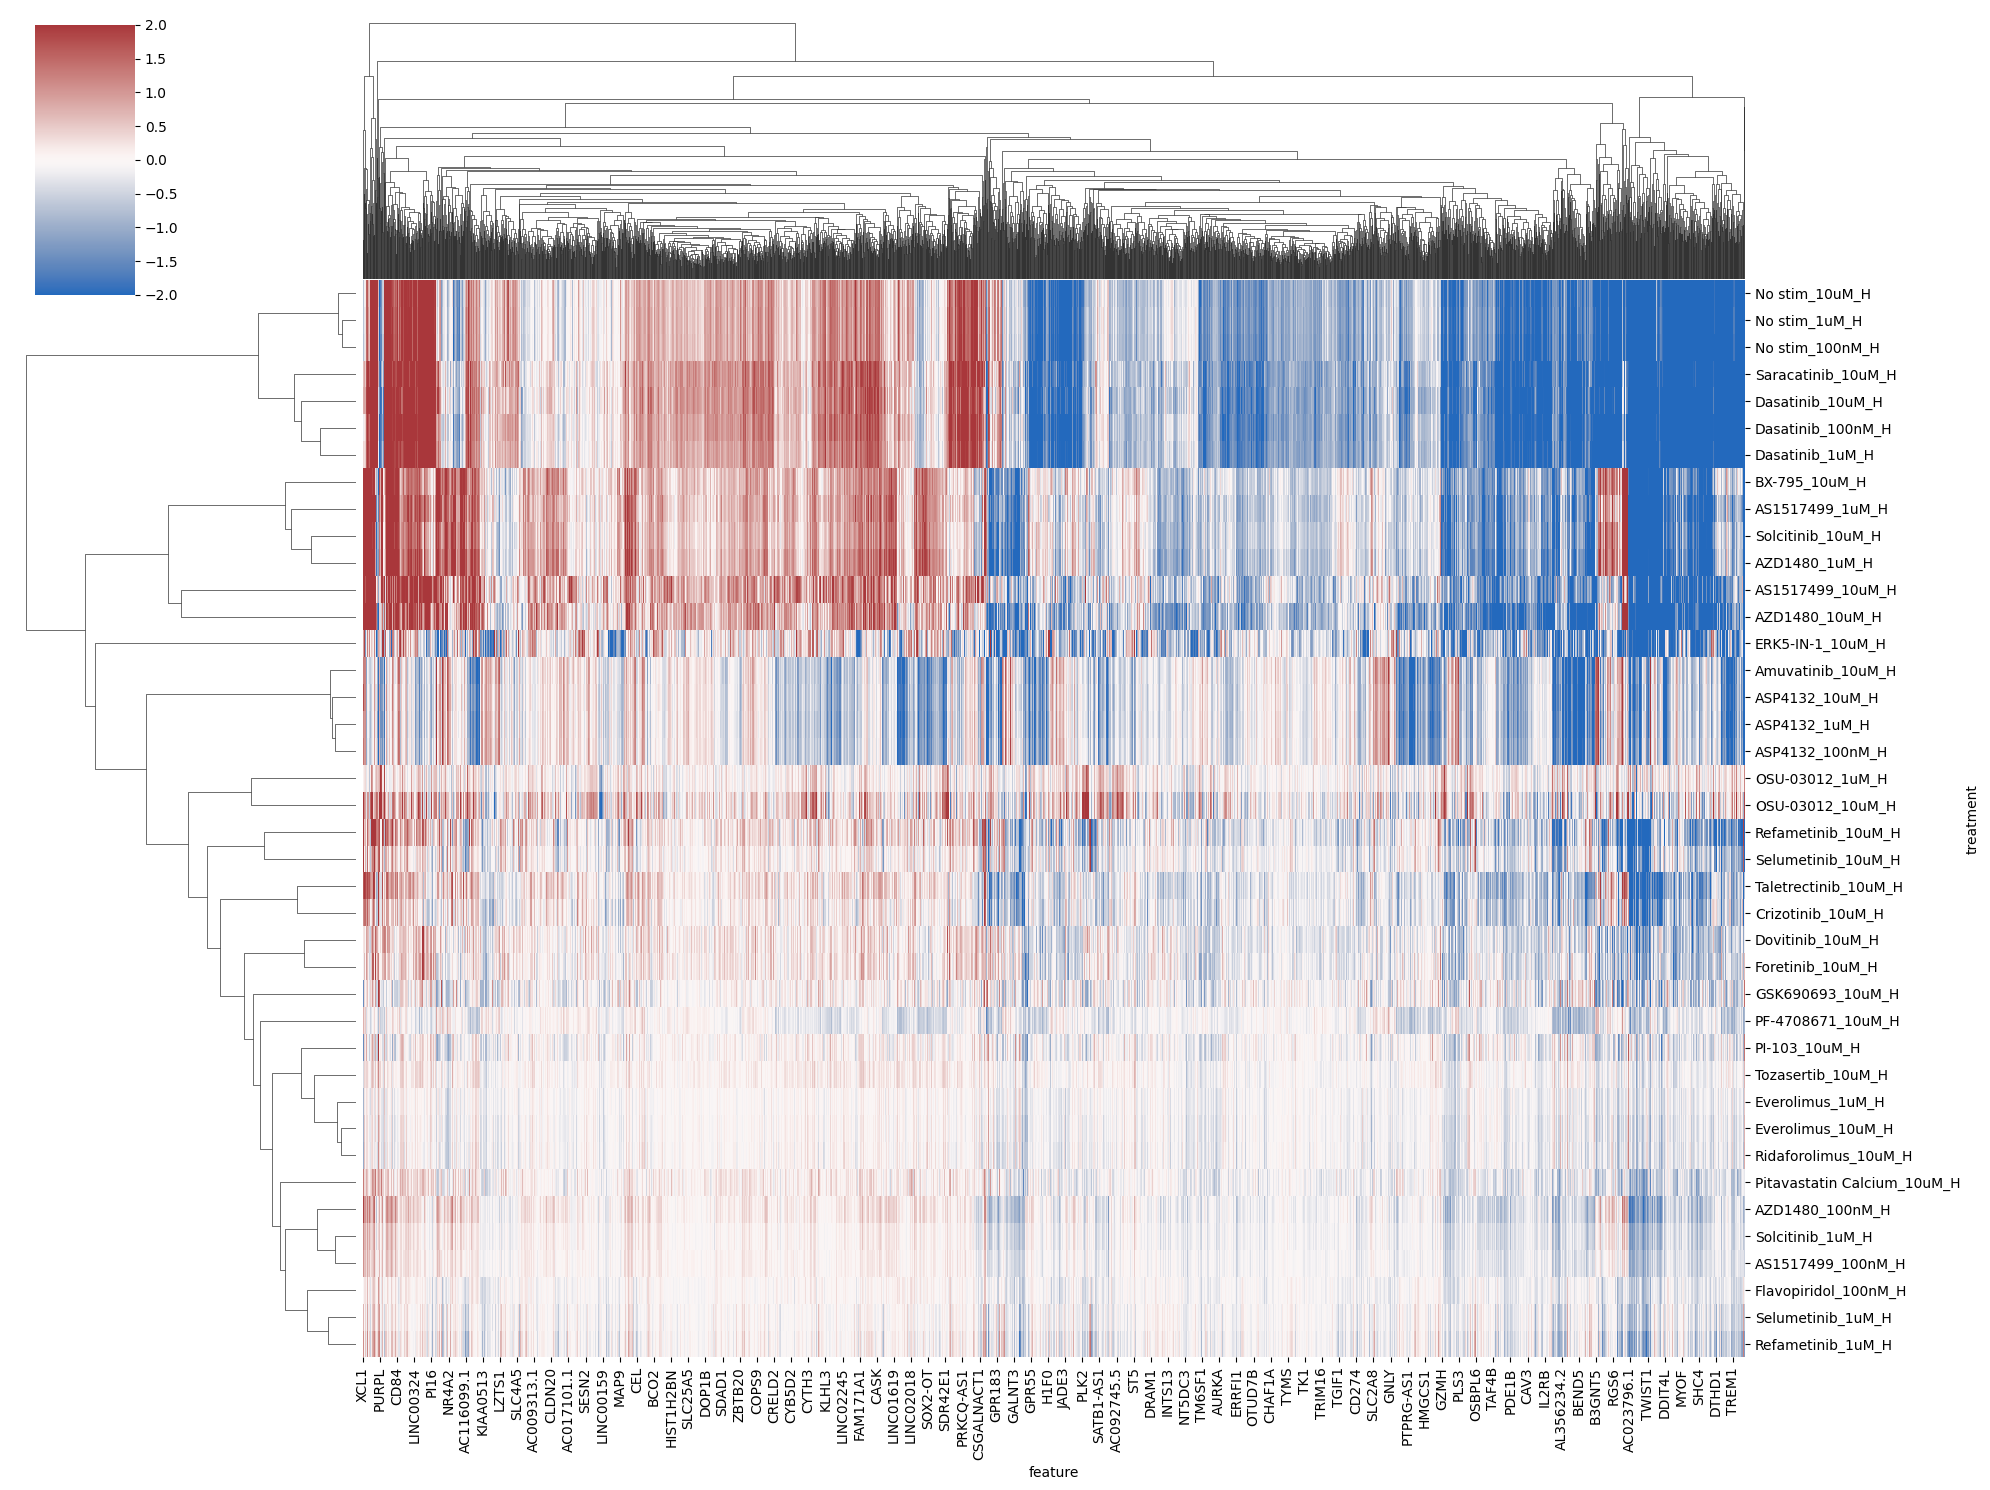

In [26]:
sns.clustermap(lfc_labeled, cmap="vlag", center=0, vmax=2, vmin=-2, figsize=(20, 15))